# Daily digital-twin run of the virtual sensors

In operation, the virtual sensors of the Nibelungen bridge are not run by hand. Once a day a scheduler starts a container that

1. queries the measured inputs of the last 15 days from the MKP data API,
2. attaches the weather with `add_weather(df)`: the wind speed and, from September 2025 on, the irradiation (the bridge pyranometer is faulty since then),
3. calls `transform(df)` of `nibelungen-virtual-sensors`, and
4. writes the predicted channels back to the data API, where the digital-twin dashboard draws them.

```
 scheduler, daily 00:30 UTC
        │ starts
        ▼
 ┌───────────── container: nibelungen-virtual-sensors ─────────────┐
 │ 1. GET   MKP data API: 3 input channels, report day − 14 d … end │
 │ 2. CALL  add_weather(df)     (wind; irradiation from Open-Meteo) │
 │ 3. CALL  transform(df)                                           │
 │ 4. POST  MKP data API: 16 result channels of the report day      │
 └─────────────────────────────────────────────────────────────────┘
        │
        ▼
 digital-twin dashboard: predicted value and 95 % band per virtual sensor
```

This notebook replays one such run: the run that fires on **2024-06-16 at 00:30 UTC** and reports **2024-06-15**. The example data `mkp_sample_2024-06-01_15.csv` (real MKP data with the MKP channel names) stands in for the data API. Everything else is the code the container runs.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Stand-in for the MKP data API |
| 3 | The job the container runs |
| 4 | Replay of the run for 2024-06-15 |
| 5 | What the dashboard shows |
| 6 | Model check: virtual twins of measured sensors |
| 7 | Failure handling |

Run time: about 10 min for the daily run and 10 min for the model check, on one CPU core.

## 1. Setup

The notebook expects the package to be installed (`pip install .` in `code/virtual_sensors`). From a plain checkout, it falls back to the source tree. The container logs to standard output, so the notebook does the same.

In [1]:
import logging
import os
import resource
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    import nibelungen_virtual_sensors as nvs
except ModuleNotFoundError:          # checkout without `pip install .`
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import nibelungen_virtual_sensors as nvs
from nibelungen_virtual_sensors import DEFAULT_INPUT_CHANNELS, add_weather, transform

EXAMPLES = Path.cwd()                # the notebook lives in code/virtual_sensors/examples

logging.basicConfig(level=logging.INFO, stream=sys.stdout, force=True,
                    format="%(asctime)s %(levelname)-7s %(name)s: %(message)s")
log = logging.getLogger("daily_job")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 1.6})
MODEL, MEASURED = "#2a78d6", "#3d3d3a"   # model: blue mean + band; measurement: neutral ink

print(f"nibelungen-virtual-sensors {nvs.__version__} from {Path(nvs.__file__).parent}")

pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


nibelungen-virtual-sensors 0.1.0 from <repository>/virtual_sensors/src/nibelungen_virtual_sensors


## 2. Stand-in for the MKP data API

The container talks to the platform through two calls:

- **`query(channels, start, end)`** returns a `Timestamp` column (UTC) and one `float64` column per channel. This is the input schema of `transform`.
- **`write(result)`** stores each returned column as a channel under its name. Re-writing a time stamp overwrites it, so a re-run of a day replaces the earlier values.

`DataAPIStub` implements both calls on the example CSV and an in-memory store. In the container, a thin HTTP client of the real MKP data API replaces it; the job code in section 3 does not change.

In [2]:
class DataAPIStub:
    # In-memory stand-in for the MKP data API.

    def __init__(self, csv_path):
        data = pd.read_csv(csv_path, parse_dates=["Timestamp"])
        data["Timestamp"] = data["Timestamp"].astype("datetime64[ns]")
        self._archive = data.set_index("Timestamp").sort_index()
        self.channels = {}           # channel name -> pd.Series, what the dashboard reads
        self.units = {}              # channel name -> unit

    def query(self, channels, start, end):
        # Measured channels between start and end (both inclusive).
        rows = self._archive.loc[pd.Timestamp(start):pd.Timestamp(end), list(channels)]
        return rows.reset_index()

    def write(self, result):
        # Upsert every result column as a channel; returns the number of values written.
        table = result.set_index("Timestamp")
        for name, unit in result.attrs["units"].items():
            for col in (name, f"{name}_std", f"{name}_lower", f"{name}_upper"):
                old = self.channels.get(col)
                self.channels[col] = table[col] if old is None else table[col].combine_first(old)
                self.units[col] = unit
        return table.size

## 3. The job the container runs

Four functions make up the container's program:

- **`run_daily_job(api, report_day)`** queries the 14 days of spin-up history plus the report day, attaches the weather, calls `transform`, checks the result and writes it. The report window travels with the frame in `df.attrs`, so the job reports the requested day even if the query returns rows after it.
- **`add_weather(df)`** (from the package) is a step of its own that only takes the frame, attaches the wind speed column and, for rows from 2025-09-01 on, replaces the faulty measured irradiation by Open-Meteo `shortwave_radiation`. It needs no model, so in a streaming set-up (e.g. Apache Kafka) it can run in its own container in front of the one that runs `transform`.
- **`check_result(result)`** rejects an incomplete or inconsistent day before anything reaches the dashboard.
- **`main(env, api)`** is the container's entry point. It reads its settings from environment variables and returns the process exit code: 0 on success, 1 on a failed day, so the scheduler can retry.

Only the three MKP channels are queried. MKP does not measure the wind speed, so `add_weather` fetches it from Open-Meteo, in the same request as the irradiation when that is needed. The replayed day (June 2024) predates the sensor fault, so it uses the measured irradiation. Without network access, set `WIND_SPEED` to a constant in m/s, e.g. `2.7`.

| Environment variable | Default | Meaning |
|---|---|---|
| `REPORT_DATE` | yesterday (UTC) | day to report, `YYYY-MM-DD`; set it to re-run a past day |
| `WIND_SPEED` | `open-meteo` | wind source if the data API has no wind channel: `open-meteo` or m/s |

In [3]:
SPIN_UP = pd.Timedelta(days=14)      # history that rebuilds the thermal state of the bridge
STEP = pd.Timedelta("30min")         # model time step = reporting step
MKP_CHANNELS = [ch for role, ch in DEFAULT_INPUT_CHANNELS.items() if role != "wind_speed"]


def check_result(result, day):
    expected = int(pd.Timedelta(days=1) / STEP)
    if len(result) != expected:
        raise RuntimeError(f"{day:%Y-%m-%d}: {len(result)} of {expected} time steps; "
                           "the inputs of the day are probably not complete yet")
    values = result.drop(columns="Timestamp")
    if not np.isfinite(values.to_numpy()).all():
        raise RuntimeError(f"{day:%Y-%m-%d}: non-finite values in the result")
    for name in result.attrs["units"]:
        if not (result[f"{name}_lower"] <= result[name]).all() or not (result[name] <= result[f"{name}_upper"]).all():
            raise RuntimeError(f"{day:%Y-%m-%d}: {name} lies outside its own interval")


def run_daily_job(api, report_day, wind_speed="open-meteo"):
    day = pd.Timestamp(report_day).normalize()
    start, end = day - SPIN_UP, day + pd.Timedelta(days=1) - STEP
    df = api.query(MKP_CHANNELS, start, end)
    df.attrs.update(report_start=day.isoformat(), report_end=end.isoformat())
    log.info("queried %d rows of %d channels, %s … %s", len(df), len(MKP_CHANNELS), start, end)

    df = add_weather(df, wind_speed)

    t0 = time.perf_counter()
    result = transform(df)
    log.info("transform: %d rows x %d columns in %.0f s", *result.shape, time.perf_counter() - t0)

    check_result(result, day)
    n = api.write(result)
    log.info("wrote %d values of %d channels for %s", n, result.shape[1] - 1, f"{day:%Y-%m-%d}")
    return result


def main(env=os.environ, api=None):
    # Container entry point; returns the exit code.
    # In the image, `api` is the HTTP client of the MKP data API, built from env (URL, token).
    yesterday = pd.Timestamp.now(tz="UTC").tz_localize(None).normalize() - pd.Timedelta(days=1)
    report_day = pd.Timestamp(env.get("REPORT_DATE") or yesterday)
    wind = env.get("WIND_SPEED", "open-meteo")
    wind = wind if wind == "open-meteo" else float(wind)
    try:
        run_daily_job(api, report_day, wind_speed=wind)
    except (ValueError, RuntimeError) as exc:     # bad or missing input, Open-Meteo down
        log.error("report of %s failed: %s", f"{report_day:%Y-%m-%d}", exc)
        return 1
    return 0

## 4. Replay of the run for 2024-06-15

The scheduler would start the container on 2024-06-16 at 00:30 UTC, and `REPORT_DATE` would default to 2024-06-15. Here `REPORT_DATE` is set explicitly, so the replay does not depend on today's date. This is also how a missed day is re-run.

In [4]:
api = DataAPIStub(EXAMPLES / "mkp_sample_2024-06-01_15.csv")

t0 = time.perf_counter()
exit_code = main({"REPORT_DATE": "2024-06-15"}, api=api)
peak_gb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2
print(f"\nexit code {exit_code}, wall time {time.perf_counter() - t0:.0f} s, "
      f"peak memory of this kernel {peak_gb:.2f} GB")

2026-10-12 14:26:48,970 INFO    daily_job: queried 720 rows of 3 channels, 2024-06-01 00:00:00 … 2024-06-15 23:30:00


2026-10-12 14:26:49,446 INFO    nibelungen_virtual_sensors.transform: wind speed: Open-Meteo wind_speed_10m, 720 values
2026-10-12 14:26:53,787 INFO    nibelungen_virtual_sensors.transform: quadrature node 1/3: c_c = 0.6116
2026-10-12 14:30:18,541 INFO    nibelungen_virtual_sensors.transform: quadrature node 2/3: c_c = 2.5089
2026-10-12 14:33:52,949 INFO    nibelungen_virtual_sensors.transform: quadrature node 3/3: c_c = 10.2916
2026-10-12 14:36:57,979 INFO    daily_job: transform: 48 rows x 17 columns in 609 s
2026-10-12 14:36:57,986 INFO    daily_job: wrote 768 values of 16 channels for 2024-06-15

exit code 0, wall time 609 s, peak memory of this kernel 0.36 GB


The data API now holds 16 new channels: four per virtual sensor of MKP's sensor IFC model `DZ-Sim_Nibelungbrücke-TUS` (measuring axis E+23.3 m). For each sensor `<name>`, the channels are:

- `<name>`: predicted value (predictive mean);
- `<name>_std`: predictive standard deviation;
- `<name>_lower`, `<name>_upper`: limits of the 95 % credible interval.

The data API stores them wide, as `transform` returns them: one column per channel, one row per time stamp:

In [5]:
stored = pd.DataFrame(api.channels).rename_axis("Timestamp")
print(f"{stored.shape[1]} channels x {len(stored)} half-hourly values, "
      f"{stored.index[0]} … {stored.index[-1]}, units: {sorted(set(api.units.values()))}")
stored.head(8)

16 channels x 48 half-hourly values, 2024-06-15 00:00:00 … 2024-06-15 23:30:00, units: ['°C']


## 5. What the dashboard shows

The dashboard reads the stored channels back and draws, for each virtual sensor, the predicted value with its 95 % band. The figure below is built only from what the data API holds.

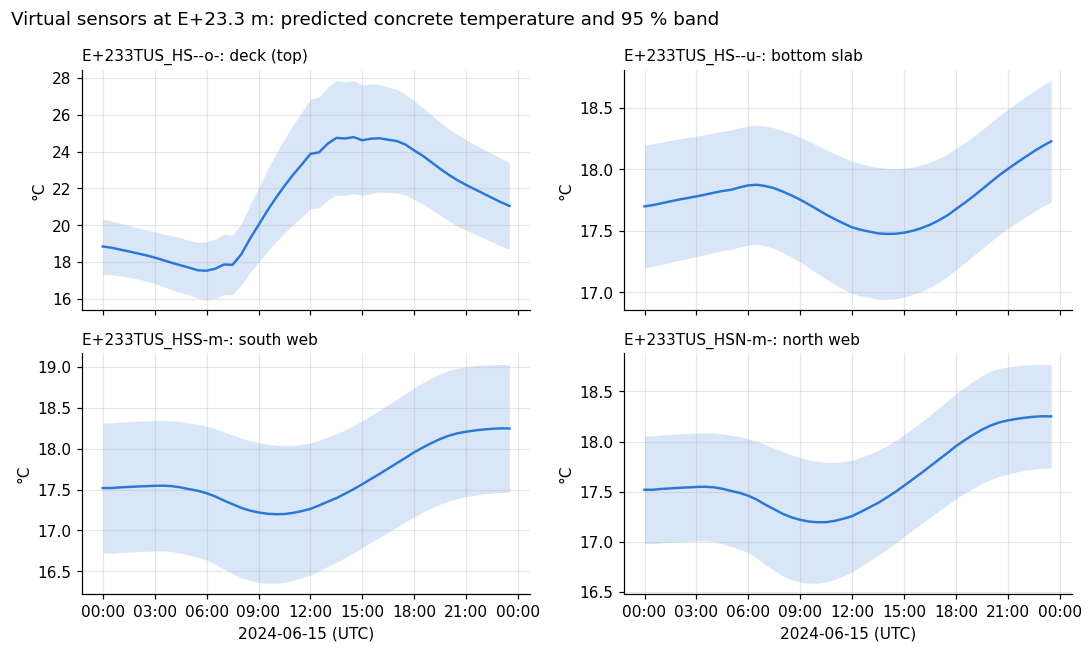

,member,min [°C],max [°C],daily range [°C],mean 95 % half-width [°C]
E+233TUS_HS--o-,deck (top),17.53,24.78,7.25,2.24
E+233TUS_HS--u-,bottom slab,17.47,18.23,0.75,0.50
E+233TUS_HSS-m-,south web,17.20,18.25,1.05,0.80
E+233TUS_HSN-m-,north web,17.19,18.25,1.06,0.55


In [6]:
MEMBER = {"HS--o-": "deck (top)", "HS--u-": "bottom slab", "HSS-m-": "south web", "HSN-m-": "north web"}
sensors = [c for c in stored.columns if not c.endswith(("_std", "_lower", "_upper"))]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, name in zip(axes.flat, sensors):
    t = stored.index.to_numpy()
    ax.fill_between(t, stored[f"{name}_lower"].to_numpy(), stored[f"{name}_upper"].to_numpy(),
                    color=MODEL, alpha=0.18, lw=0)
    ax.plot(t, stored[name].to_numpy(), color=MODEL)
    ax.set_title(f"{name}: {MEMBER[name.split('_', 1)[1]]}", fontsize=10, loc="left")
    ax.set_ylabel(api.units[name])
for ax in axes[1]:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
    ax.set_xlabel("2024-06-15 (UTC)")
fig.suptitle("Virtual sensors at E+23.3 m: predicted concrete temperature and 95 % band", x=0.01, ha="left")
fig.tight_layout()
plt.show()

summary = pd.DataFrame({
    "member": [MEMBER[n.split("_", 1)[1]] for n in sensors],
    "min [°C]": [stored[n].min() for n in sensors],
    "max [°C]": [stored[n].max() for n in sensors],
    "daily range [°C]": [stored[n].max() - stored[n].min() for n in sensors],
    "mean 95 % half-width [°C]": [(stored[f"{n}_upper"] - stored[n]).mean() for n in sensors],
}, index=sensors)
summary.round(2)

## 6. Model check: virtual twins of measured sensors

The sensors at E+23.3 m are virtual, so their predictions cannot be checked directly. A digital twin can, however, place virtual sensors at the positions of *measured* MKP sensors and compare both. A drift of this comparison over time signals that the model no longer fits the bridge. The check below runs once for the report day; operated daily, it would be a second, optional job.

The twins are the four temperature sensors of the pilot section E+4.0 m (model `z = 0`, calibrated positions and errors) and the inclinometer at E+42.3 m (model `z = 38.3`). They are the same as in `demo.py`. The inclinometer has an arbitrary zero, so the tilt is compared after removing the mean offset of the day.

In [7]:
TWINS = {
    "E_plus_040TU_HS--o-_Avg1": {"quantity": "temperature", "position": [2.85, -0.1813, 0.0], "noise_std": 0.3879},
    "E_plus_040TU_HS--u-_Avg1": {"quantity": "temperature", "position": [2.85, -5.2659, 0.0], "noise_std": 0.2460},
    "E_plus_040TU_HSS-m-_Avg1": {"quantity": "temperature", "position": [3.4506, -2.63, 0.0], "noise_std": 0.3962},
    "E_plus_040TU_HSN-m-_Avg1": {"quantity": "temperature", "position": [2.0685, -2.63, 0.0], "noise_std": 0.2587},
    "E_plus_423NU_HSN-o-_Avg1": {"quantity": "inclination", "position": [-2.25, -0.2, 38.3]},
}
TWIN_LABEL = {"E_plus_040TU_HS--o-_Avg1": "E+4.0 deck (top)", "E_plus_040TU_HS--u-_Avg1": "E+4.0 bottom slab",
              "E_plus_040TU_HSS-m-_Avg1": "E+4.0 south web", "E_plus_040TU_HSN-m-_Avg1": "E+4.0 north web",
              "E_plus_423NU_HSN-o-_Avg1": "E+42.3 inclinometer"}

day = pd.Timestamp("2024-06-15")
start, end = day - SPIN_UP, day + pd.Timedelta(days=1) - STEP
inputs = api.query(MKP_CHANNELS, start, end)
inputs.attrs.update(report_start=day.isoformat(), report_end=end.isoformat())
measured = api.query(list(TWINS), day, end).set_index("Timestamp")

t0 = time.perf_counter()
twins = transform(add_weather(inputs), [{"name": k, **v} for k, v in TWINS.items()]).set_index("Timestamp")
print(f"model check: {time.perf_counter() - t0:.0f} s")

rows = {}
for k, spec in TWINS.items():
    y, m = measured[k].to_numpy(), twins[k].to_numpy()
    if spec["quantity"] == "inclination":
        r = (y - y.mean()) - (m - m.mean())
        inside = np.nan
    else:
        r = y - m
        inside = np.mean((y >= twins[f"{k}_lower"]) & (y <= twins[f"{k}_upper"]))
    rows[TWIN_LABEL[k]] = {"unit": twins.attrs["units"][k], "correlation": np.corrcoef(y, m)[0, 1],
                           "RMSE": np.sqrt(np.mean(r ** 2)), "inside 95 % band": inside}
check = pd.DataFrame(rows).T
for col, fmt in {"correlation": "{:.2f}", "RMSE": "{:.2f}", "inside 95 % band": "{:.0%}"}.items():
    check[col] = ["–" if pd.isna(v) else fmt.format(v) for v in check[col]]
check

2026-10-12 14:36:59,178 INFO    nibelungen_virtual_sensors.transform: wind speed: Open-Meteo wind_speed_10m, 720 values
2026-10-12 14:38:18,833 INFO    nibelungen_virtual_sensors.fem.mechanics: adjoint solve: 43 GMRES iterations
2026-10-12 14:38:18,934 INFO    nibelungen_virtual_sensors.transform: quadrature node 1/3: c_c = 0.6116
2026-10-12 14:41:25,129 INFO    nibelungen_virtual_sensors.transform: quadrature node 2/3: c_c = 2.5089
2026-10-12 14:44:29,025 INFO    nibelungen_virtual_sensors.transform: quadrature node 3/3: c_c = 10.2916
model check: 623 s


,unit,correlation,RMSE,inside 95 % band
E+4.0 deck (top),°C,0.98,0.51,100%
E+4.0 bottom slab,°C,-0.04,0.18,100%
E+4.0 south web,°C,0.80,0.42,100%
E+4.0 north web,°C,1.00,0.08,100%
E+42.3 inclinometer,mm/m,0.99,0.15,–


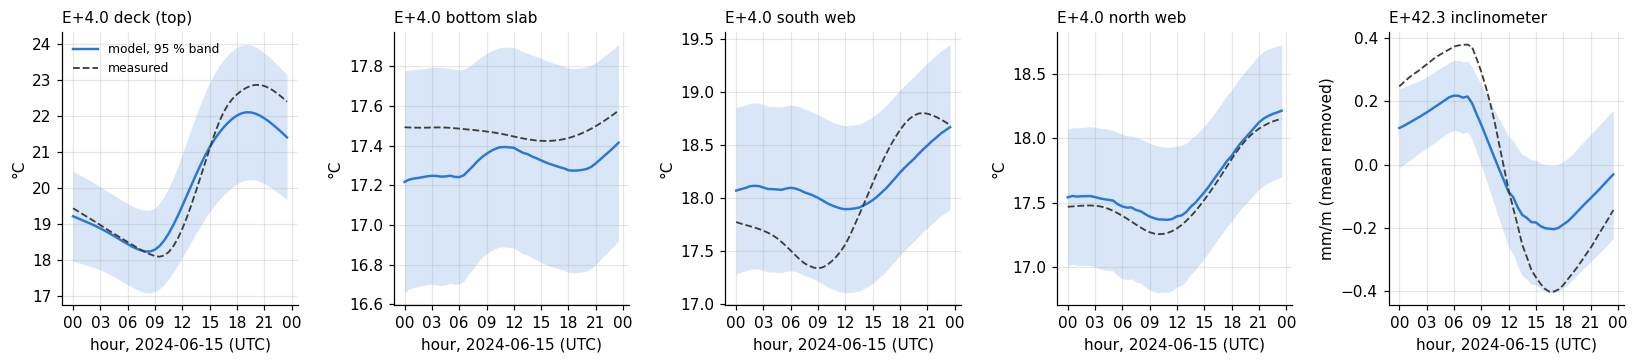

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharex=True)
for ax, (k, spec) in zip(axes, TWINS.items()):
    t, y, m = measured.index.to_numpy(), measured[k].to_numpy(), twins[k].to_numpy()
    lo, hi = twins[f"{k}_lower"].to_numpy(), twins[f"{k}_upper"].to_numpy()
    if spec["quantity"] == "inclination":     # arbitrary zero: compare changes
        shift_y, shift_m = y.mean(), m.mean()
        y, m, lo, hi = y - shift_y, m - shift_m, lo - shift_m, hi - shift_m
    ax.fill_between(t, lo, hi, color=MODEL, alpha=0.18, lw=0)
    ax.plot(t, m, color=MODEL, label="model, 95 % band")
    ax.plot(t, y, color=MEASURED, lw=1.2, ls="--", label="measured")
    ax.set_title(TWIN_LABEL[k], fontsize=10, loc="left")
    ax.set_ylabel(twins.attrs["units"][k] + (" (mean removed)" if spec["quantity"] == "inclination" else ""))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H"))
    ax.set_xlabel("hour, 2024-06-15 (UTC)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

The bottom-slab temperature barely changes in a day (±0.1 °C, below the sensor noise), so its correlation carries no information; its RMSE and band coverage do. The known limitations of the model (winter bias, no asphalt layer, no lateral sun) are listed in the package README.

## 7. Failure handling

The job never writes a partial or doubtful day. Each failure ends with exit code 1 and a log line naming the cause, and the scheduler retries later. Re-running a day is safe: the same inputs give the same output, and the data API overwrites the earlier values.

| Cause | Raised by | What happens |
|---|---|---|
| Input channel missing or empty | `transform`: `ValueError` | exit 1; fix the data, re-run with `REPORT_DATE` |
| Report day not (fully) in the data API yet | `transform`: `ValueError`, or `check_result`: `RuntimeError` | exit 1; the retry picks the day up |
| Open-Meteo unreachable | `add_weather`: `RuntimeError` | exit 1; retry, or set `WIND_SPEED` |
| Inconsistent result | `check_result`: `RuntimeError` | exit 1; nothing written; report to BAM |

The first case is the most common in operation: the job starts before the data of the report day have reached the data API. In the stand-in, this is a run for 2024-06-16, a day the example data do not contain:

In [9]:
n_before = sum(len(s) for s in api.channels.values())
exit_code = main({"REPORT_DATE": "2024-06-16"}, api=api)
n_after = sum(len(s) for s in api.channels.values())
print(f"\nexit code {exit_code}; values in the data API before/after: {n_before}/{n_after}")

2026-10-12 14:47:21,940 INFO    daily_job: queried 672 rows of 3 channels, 2024-06-02 00:00:00 … 2024-06-16 23:30:00
2026-10-12 14:47:22,446 INFO    nibelungen_virtual_sensors.transform: wind speed: Open-Meteo wind_speed_10m, 672 values
2026-10-12 14:47:22,455 ERROR   daily_job: report of 2024-06-16 failed: no input rows inside the report window [2024-06-16 00:00:00, 2024-06-16 23:30:00]

exit code 1; values in the data API before/after: 768/768
